<a href="https://colab.research.google.com/github/guisixninesix-commits/quant/blob/main/Lista3_FGV_Quant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**LISTA 3**

**Portfólios**

Exercício 1

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

usuario = "guisixninesix-commits"
repositorio = "quant"
branch = "main"

arquivos = [
    "economatica (1).xlsx",
    "economatica (2).xlsx",
    "economatica (3).xlsx",
    "economatica (4).xlsx",
    "economatica (5).xlsx",
    "economatica (6).xlsx"
]

for arquivo in arquivos:

    url = (
        f"https://raw.githubusercontent.com/"
        f"{usuario}/{repositorio}/{branch}/{arquivo}"
    )

    resposta = requests.get(url)

    print(arquivo, resposta.status_code)
    print(url)

    resposta.raise_for_status()

    with open(arquivo, "wb") as f:
        f.write(resposta.content)

print("Arquivos baixados com sucesso.")

economatica (1).xlsx 200
https://raw.githubusercontent.com/guisixninesix-commits/quant/main/economatica (1).xlsx
economatica (2).xlsx 200
https://raw.githubusercontent.com/guisixninesix-commits/quant/main/economatica (2).xlsx
economatica (3).xlsx 200
https://raw.githubusercontent.com/guisixninesix-commits/quant/main/economatica (3).xlsx
economatica (4).xlsx 200
https://raw.githubusercontent.com/guisixninesix-commits/quant/main/economatica (4).xlsx
economatica (5).xlsx 200
https://raw.githubusercontent.com/guisixninesix-commits/quant/main/economatica (5).xlsx
economatica (6).xlsx 200
https://raw.githubusercontent.com/guisixninesix-commits/quant/main/economatica (6).xlsx
Arquivos baixados com sucesso.


In [32]:
# Ler os arquivos
abev3 = pd.read_excel("economatica (1).xlsx", header=3).iloc[:, :2]
bbdc4 = pd.read_excel("economatica (2).xlsx", header=3).iloc[:, :2]
itub4 = pd.read_excel("economatica (3).xlsx", header=3).iloc[:, :2]
petr4 = pd.read_excel("economatica (4).xlsx", header=3).iloc[:, :2]
vale3 = pd.read_excel("economatica (5).xlsx", header=3).iloc[:, :2]

# Renomear colunas
abev3.columns = ["Data", "ABEV3"]
bbdc4.columns = ["Data", "BBDC4"]
itub4.columns = ["Data", "ITUB4"]
petr4.columns = ["Data", "PETR4"]
vale3.columns = ["Data", "VALE3"]

# Transformar Data em data e preços em números
for df, ativo in [
    (abev3, "ABEV3"),
    (bbdc4, "BBDC4"),
    (itub4, "ITUB4"),
    (petr4, "PETR4"),
    (vale3, "VALE3")
]:
    df["Data"] = pd.to_datetime(df["Data"], errors="coerce")
    df[ativo] = pd.to_numeric(df[ativo], errors="coerce")
    df.dropna(inplace=True)
    df.set_index("Data", inplace=True)

# Juntar apenas as datas existentes em todos os ativos
precos = pd.concat(
    [abev3, bbdc4, itub4, petr4, vale3],
    axis=1,
    join="inner"
)

precos = precos.loc["2017-01-01":"2026-10-05"]

# Calcular retornos
retornos = precos.pct_change(fill_method=None).dropna()

# Dados anualizados
retorno_medio = retornos.mean() * 252
cov_anual = retornos.cov() * 252

print(precos.dtypes)
print()
print(precos.head())

ABEV3    float64
BBDC4    float64
ITUB4    float64
PETR4    float64
VALE3    float64
dtype: object

                ABEV3     BBDC4     ITUB4     PETR4      VALE3
Data                                                          
2017-01-02  10.923985  8.577171  9.284408  3.463567  12.124163
2017-01-03  11.145009  8.940444  9.677604  3.662025  12.661187
2017-01-04  11.057939  8.883821  9.719139  3.662025  12.433799
2017-01-05  11.118219  8.982166  9.852050  3.721090  12.907928
2017-01-06  11.024450  9.038789  9.885278  3.699827  12.564426


In [33]:
# Fixar a simulação para obter sempre os mesmos resultados
np.random.seed(42)

n_portfolios = 10000

resultados = np.zeros((3, n_portfolios))
pesos_portfolios = []

for i in range(n_portfolios):

    pesos = np.random.random(len(retornos.columns))
    pesos = pesos / np.sum(pesos)

    retorno_portfolio = np.sum(pesos * retorno_medio)

    volatilidade_portfolio = np.sqrt(
        np.dot(pesos.T, np.dot(cov_anual, pesos))
    )

    sharpe = retorno_portfolio / volatilidade_portfolio

    resultados[0, i] = retorno_portfolio
    resultados[1, i] = volatilidade_portfolio
    resultados[2, i] = sharpe

    pesos_portfolios.append(pesos)

In [34]:
# Índice de Sharpe, assumindo taxa livre de risco igual a zero
indice_max_sharpe = np.argmax(resultados[2])

pesos_max_sharpe = pesos_portfolios[indice_max_sharpe]

retorno_max_sharpe = resultados[0, indice_max_sharpe]
volatilidade_max_sharpe = resultados[1, indice_max_sharpe]
sharpe_maximo = resultados[2, indice_max_sharpe]

print("Pesos do portfólio de máximo Sharpe:")

for ativo, peso in zip(retornos.columns, pesos_max_sharpe):
    print(ativo, ":", round(peso * 100, 2), "%")

print()
print("Retorno anualizado:", round(retorno_max_sharpe * 100, 2), "%")
print("Volatilidade anualizada:", round(volatilidade_max_sharpe * 100, 2), "%")
print("Índice de Sharpe:", round(sharpe_maximo, 3))

Pesos do portfólio de máximo Sharpe:
ABEV3 : 1.27 %
BBDC4 : 1.12 %
ITUB4 : 26.39 %
PETR4 : 41.56 %
VALE3 : 29.66 %

Retorno anualizado: 28.78 %
Volatilidade anualizada: 27.96 %
Índice de Sharpe: 1.029


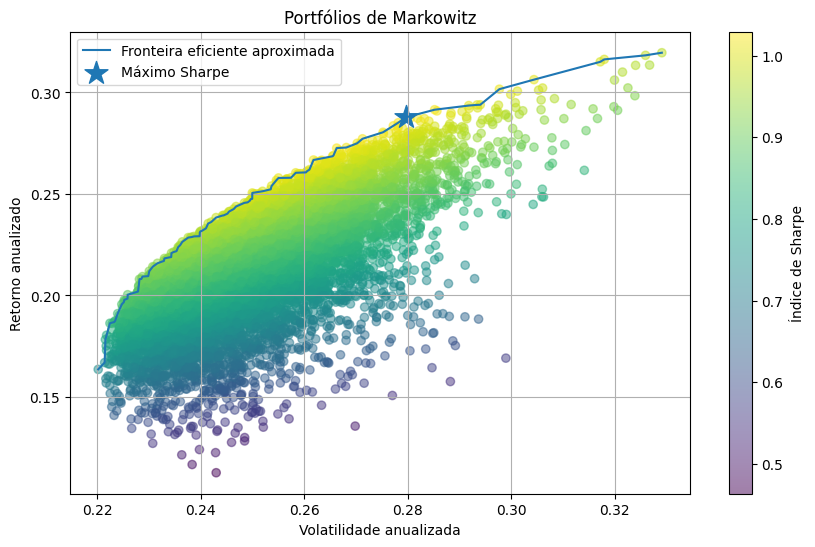

In [35]:
carteiras = pd.DataFrame({
    "Retorno": resultados[0],
    "Volatilidade": resultados[1],
    "Sharpe": resultados[2]
})

# Aproximação da fronteira eficiente
fronteira = carteiras.sort_values("Volatilidade")
fronteira = fronteira[
    fronteira["Retorno"] >= fronteira["Retorno"].cummax()
]

plt.figure(figsize=(10,6))

plt.scatter(
    resultados[1],
    resultados[0],
    c=resultados[2],
    cmap="viridis",
    alpha=0.5
)

plt.colorbar(label="Índice de Sharpe")

plt.plot(
    fronteira["Volatilidade"],
    fronteira["Retorno"],
    label="Fronteira eficiente aproximada"
)

plt.scatter(
    volatilidade_max_sharpe,
    retorno_max_sharpe,
    marker="*",
    s=300,
    label="Máximo Sharpe"
)

plt.xlabel("Volatilidade anualizada")
plt.ylabel("Retorno anualizado")
plt.title("Portfólios de Markowitz")

plt.legend()
plt.grid(True)
plt.show()

O gráfico apresenta diferentes combinações possíveis de pesos entre as cinco ações analisadas. No eixo horizontal está a volatilidade anualizada, que representa o risco, e no eixo vertical está o retorno anualizado esperado. A fronteira eficiente corresponde à região superior da nuvem de pontos, formada pelos portfólios que oferecem o maior retorno possível para determinado nível de risco.

Entre os 10.000 portfólios simulados, o maior Índice de Sharpe foi obtido com aproximadamente 1,27% em ABEV3, 1,12% em BBDC4, 26,39% em ITUB4, 41,56% em PETR4 e 29,66% em VALE3.

Esse portfólio apresentou retorno anualizado de 28,78%, volatilidade anualizada de 27,96% e Índice de Sharpe de 1,029.

Assim, essa combinação apresentou a melhor relação entre retorno e risco entre os portfólios simulados.

Exercício 2

In [36]:
# Portfólio antigo: pesos iguais
pesos_iguais = np.array([0.20, 0.20, 0.20, 0.20, 0.20])

retorno_igual = np.sum(pesos_iguais * retorno_medio)

volatilidade_igual = np.sqrt(
    np.dot(pesos_iguais.T, np.dot(cov_anual, pesos_iguais))
)

sharpe_igual = retorno_igual / volatilidade_igual

print("Portfólio com pesos iguais:")
print("Retorno anualizado:", round(retorno_igual * 100, 2), "%")
print("Volatilidade anualizada:", round(volatilidade_igual * 100, 2), "%")
print("Índice de Sharpe:", round(sharpe_igual, 3))

Portfólio com pesos iguais:
Retorno anualizado: 21.35 %
Volatilidade anualizada: 24.27 %
Índice de Sharpe: 0.88


In [37]:
comparacao = pd.DataFrame({
    "Pesos iguais": [
        retorno_igual,
        volatilidade_igual,
        sharpe_igual
    ],
    "Máximo Sharpe": [
        retorno_max_sharpe,
        volatilidade_max_sharpe,
        sharpe_maximo
    ]
},
    index=[
        "Retorno anualizado",
        "Volatilidade anualizada",
        "Índice de Sharpe"
    ]
)

comparacao

,Pesos iguais,Máximo Sharpe
Retorno anualizado,0.213522,0.287821
Volatilidade anualizada,0.242718,0.279649
Índice de Sharpe,0.879712,1.029221


In [38]:
retorno_portfolio_igual = retornos.dot(pesos_iguais)

retorno_portfolio_otimizado = retornos.dot(pesos_max_sharpe)

acumulado_igual = (1 + retorno_portfolio_igual).cumprod() * 100

acumulado_otimizado = (1 + retorno_portfolio_otimizado).cumprod() * 100

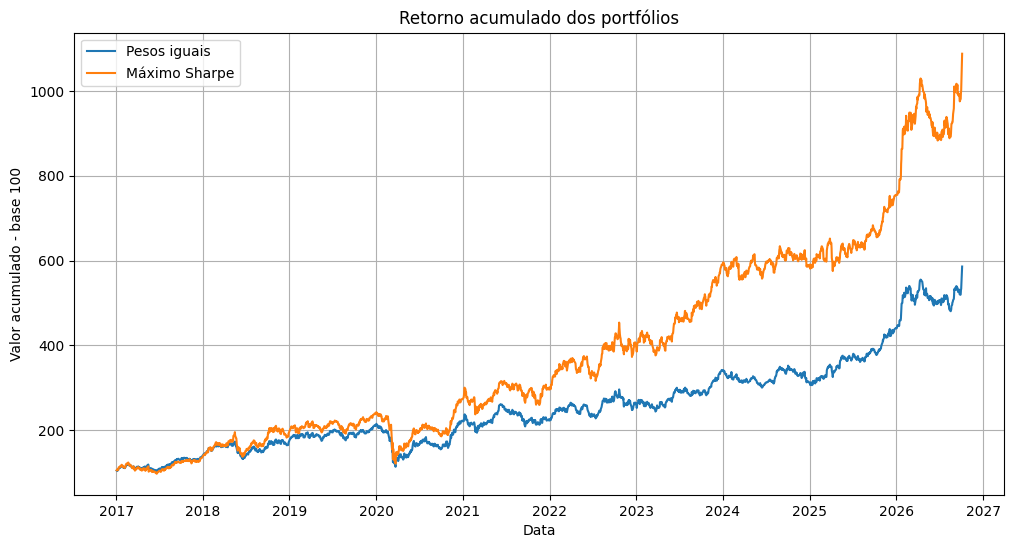

Valor final - Pesos iguais: 585.88
Valor final - Máximo Sharpe: 1088.35


In [39]:
plt.figure(figsize=(12,6))

plt.plot(
    acumulado_igual,
    label="Pesos iguais"
)

plt.plot(
    acumulado_otimizado,
    label="Máximo Sharpe"
)

plt.xlabel("Data")
plt.ylabel("Valor acumulado - base 100")
plt.title("Retorno acumulado dos portfólios")

plt.legend()
plt.grid(True)

plt.show()

print("Valor final - Pesos iguais:", round(acumulado_igual.iloc[-1], 2))
print("Valor final - Máximo Sharpe:", round(acumulado_otimizado.iloc[-1], 2))

O portfólio de máximo Sharpe apresentou desempenho superior ao portfólio com pesos iguais. O retorno anualizado aumentou de aproximadamente 21,35% para 28,78%, enquanto a volatilidade passou de 24,27% para 27,96%.

Apesar do aumento do risco, o retorno cresceu proporcionalmente mais, fazendo com que o Índice de Sharpe aumentasse de aproximadamente 0,880 para 1,029. Assim, o portfólio otimizado apresentou uma melhor relação entre retorno e risco.

Essa diferença também aparece no gráfico de retornos acumulados. Partindo de uma base 100, o portfólio com pesos iguais terminou em aproximadamente 585,88, enquanto o portfólio de máximo Sharpe chegou a 1088,35. Portanto, a ponderação dos ativos melhorou de forma relevante o desempenho do portfólio no período analisado.

Exercício 3

In [40]:
!pip install -q nefin

import nefin as nd
import statsmodels.api as sm

fatores = nd.load_risk_factors()

dados_modelos = pd.DataFrame({
    "portfolio": retorno_portfolio_otimizado
})

dados_modelos = dados_modelos.join(
    fatores[["rm_minus_rf", "smb", "hml", "risk_free"]],
    how="inner"
)

dados_modelos = dados_modelos.dropna()

dados_modelos["excesso_portfolio"] = (
    dados_modelos["portfolio"] - dados_modelos["risk_free"]
)

y = dados_modelos["excesso_portfolio"]

X_capm = dados_modelos[["rm_minus_rf"]]
X_capm = sm.add_constant(X_capm)

modelo_capm = sm.OLS(y, X_capm).fit()

print(modelo_capm.summary())

X_ff3 = dados_modelos[
    ["rm_minus_rf", "smb", "hml"]
]

X_ff3 = sm.add_constant(X_ff3)

modelo_ff3 = sm.OLS(y, X_ff3).fit()

print(modelo_ff3.summary())

rf_medio = dados_modelos["risk_free"].mean()

premio_mercado = dados_modelos["rm_minus_rf"].mean()
smb_medio = dados_modelos["smb"].mean()
hml_medio = dados_modelos["hml"].mean()

beta_capm = modelo_capm.params["rm_minus_rf"]

retorno_esperado_capm_diario = (
    rf_medio +
    beta_capm * premio_mercado
)

retorno_esperado_capm_anual = (
    retorno_esperado_capm_diario * 252
)

beta_mercado_ff3 = modelo_ff3.params["rm_minus_rf"]
beta_smb = modelo_ff3.params["smb"]
beta_hml = modelo_ff3.params["hml"]

retorno_esperado_ff3_diario = (
    rf_medio
    + beta_mercado_ff3 * premio_mercado
    + beta_smb * smb_medio
    + beta_hml * hml_medio
)

retorno_esperado_ff3_anual = (
    retorno_esperado_ff3_diario * 252
)

print(
    "Retorno esperado anual - CAPM:",
    round(retorno_esperado_capm_anual * 100, 2),
    "%"
)

print(
    "Retorno esperado anual - Fama-French 3 fatores:",
    round(retorno_esperado_ff3_anual * 100, 2),
    "%"
)

print()
print("Beta CAPM:", round(beta_capm, 4))
print("Beta mercado FF3:", round(beta_mercado_ff3, 4))
print("Beta SMB:", round(beta_smb, 4))
print("Beta HML:", round(beta_hml, 4))

                            OLS Regression Results                            
Dep. Variable:      excesso_portfolio   R-squared:                       0.734
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     6631.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:56:13   Log-Likelihood:                 7890.4
No. Observations:                2404   AIC:                        -1.578e+04
Df Residuals:                    2402   BIC:                        -1.577e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.0005      0.000      2.816      

Pelo modelo CAPM, o retorno esperado anual do portfólio foi de aproximadamente 15,05%. Já pelo modelo Fama-French de três fatores, o retorno esperado foi de aproximadamente 22,57%.

A diferença ocorre porque o CAPM considera apenas a exposição do portfólio ao risco de mercado, enquanto o modelo Fama-French também incorpora os fatores tamanho (SMB) e valor (HML).

No modelo Fama-French, o portfólio apresentou beta de mercado de 1,0111, beta SMB de -0,2786 e beta HML de 0,5007. O coeficiente negativo de SMB indica maior exposição relativa a empresas grandes, enquanto o coeficiente positivo de HML indica exposição ao fator valor.

O modelo Fama-French também apresentou maior poder explicativo, com R² de aproximadamente 0,880, contra 0,734 no CAPM. Assim, os fatores adicionais ajudam a explicar parte do retorno do portfólio que não é capturada apenas pelo risco de mercado.

**Derivativos**

Exercício 1

In [41]:
import sympy as sp

S, K, r, T, sigma = sp.symbols(
    'S K r T sigma',
    positive=True
)

N = sp.Function('N')

d1 = (
    sp.log(S / K)
    + (r + sigma**2 / 2) * T
) / (sigma * sp.sqrt(T))

d2 = d1 - sigma * sp.sqrt(T)

call = S * N(d1) - K * sp.exp(-r * T) * N(d2)

put = K * sp.exp(-r * T) * N(-d2) - S * N(-d1)

print("d1:")
sp.pprint(d1)

print("\nd2:")
sp.pprint(d2)

print("\nPreço da Call:")
sp.pprint(call)

print("\nPreço da Put:")
sp.pprint(put)

d1:
  ⎛     2⎞         
  ⎜    σ ⎟      ⎛S⎞
T⋅⎜r + ──⎟ + log⎜─⎟
  ⎝    2 ⎠      ⎝K⎠
───────────────────
       √T⋅σ        

d2:
          ⎛     2⎞         
          ⎜    σ ⎟      ⎛S⎞
        T⋅⎜r + ──⎟ + log⎜─⎟
          ⎝    2 ⎠      ⎝K⎠
-√T⋅σ + ───────────────────
               √T⋅σ        

Preço da Call:
     ⎛          ⎛     2⎞         ⎞            ⎛  ⎛     2⎞         ⎞
     ⎜          ⎜    σ ⎟      ⎛S⎞⎟            ⎜  ⎜    σ ⎟      ⎛S⎞⎟
     ⎜        T⋅⎜r + ──⎟ + log⎜─⎟⎟            ⎜T⋅⎜r + ──⎟ + log⎜─⎟⎟
     ⎜          ⎝    2 ⎠      ⎝K⎠⎟  -T⋅r      ⎜  ⎝    2 ⎠      ⎝K⎠⎟
- K⋅N⎜-√T⋅σ + ───────────────────⎟⋅ℯ     + S⋅N⎜───────────────────⎟
     ⎝               √T⋅σ        ⎠            ⎝       √T⋅σ        ⎠

Preço da Put:
   ⎛         ⎛     2⎞         ⎞            ⎛ ⎛  ⎛     2⎞         ⎞ ⎞
   ⎜         ⎜    σ ⎟      ⎛S⎞⎟            ⎜ ⎜  ⎜    σ ⎟      ⎛S⎞⎟ ⎟
   ⎜       T⋅⎜r + ──⎟ + log⎜─⎟⎟            ⎜-⎜T⋅⎜r + ──⎟ + log⎜─⎟⎟ ⎟
   ⎜         ⎝    2 ⎠      ⎝K⎠⎟  -T⋅r      ⎜ ⎝  ⎝    2 ⎠ 

O modelo Black-Scholes é utilizado como referência para calcular o preço teórico de opções.

Na fórmula, S representa o preço atual do ativo, K o preço de exercício, r a taxa livre de risco, T o tempo até o vencimento e σ a volatilidade do ativo. Já N(d1) e N(d2) correspondem à distribuição normal acumulada.

A partir dessas variáveis, o modelo estima o valor teórico de uma opção de compra (call) ou de venda (put).

Exercício 2

In [42]:
import numpy as np
from scipy.stats import norm

# Parâmetros
S = 100
K = 100
r = 0.10
T = 1
sigma = 0.20

# d1 e d2
d1 = (
    np.log(S / K)
    + (r + sigma**2 / 2) * T
) / (sigma * np.sqrt(T))

d2 = d1 - sigma * np.sqrt(T)

# Preço da Call
C = (
    S * norm.cdf(d1)
    - K * np.exp(-r * T) * norm.cdf(d2)
)

# Preço da Put
P = (
    K * np.exp(-r * T) * norm.cdf(-d2)
    - S * norm.cdf(-d1)
)

# Put-Call Parity
lado_esquerdo = C + K * np.exp(-r * T)
lado_direito = P + S

print("Preço da Call:", round(C, 2))
print("Preço da Put:", round(P, 2))

print()
print("Call + valor presente de K:", round(lado_esquerdo, 2))
print("Put + preço da ação:", round(lado_direito, 2))

Preço da Call: 13.27
Preço da Put: 3.75

Call + valor presente de K: 103.75
Put + preço da ação: 103.75


A simulação confirmou a relação de put-call parity. O valor de \(C + Ke^{-rT}\) foi 103,75, exatamente igual ao valor de \(P + S\), também de 103,75.

A intuição é que essas duas combinações geram o mesmo resultado no vencimento e, portanto, devem ter o mesmo valor hoje, caso essa igualdade não fosse respeitada, existiria uma oportunidade de arbitragem.

Exercício 3

In [47]:
import sympy as sp

S, K, r, T, sigma = sp.symbols(
    'S K r T sigma',
    positive=True
)

N = sp.Function('N')

d1 = (
    sp.log(S / K)
    + (r + sigma**2 / 2) * T
) / (sigma * sp.sqrt(T))

d2 = d1 - sigma * sp.sqrt(T)

# Densidade da normal padrão
phi_d1 = (
    1 / sp.sqrt(2 * sp.pi)
) * sp.exp(-(d1**2) / 2)

# DELTA
delta_call = N(d1)
delta_put = N(d1) - 1

# GAMMA
gamma = phi_d1 / (S * sigma * sp.sqrt(T))

# VEGA
vega = S * phi_d1 * sp.sqrt(T)

# THETA
theta_call = (
    -(S * phi_d1 * sigma) / (2 * sp.sqrt(T))
    - r * K * sp.exp(-r * T) * N(d2)
)

theta_put = (
    -(S * phi_d1 * sigma) / (2 * sp.sqrt(T))
    + r * K * sp.exp(-r * T) * N(-d2)
)

print("Delta da Call:")
sp.pprint(delta_call)

print("\nDelta da Put:")
sp.pprint(delta_put)

print("\nGamma:")
sp.pprint(gamma)

print("\nVega:")
sp.pprint(vega)

print("\nTheta da Call:")
sp.pprint(theta_call)

print("\nTheta da Put:")
sp.pprint(theta_put)

Delta da Call:
 ⎛  ⎛     2⎞         ⎞
 ⎜  ⎜    σ ⎟      ⎛S⎞⎟
 ⎜T⋅⎜r + ──⎟ + log⎜─⎟⎟
 ⎜  ⎝    2 ⎠      ⎝K⎠⎟
N⎜───────────────────⎟
 ⎝       √T⋅σ        ⎠

Delta da Put:
 ⎛  ⎛     2⎞         ⎞    
 ⎜  ⎜    σ ⎟      ⎛S⎞⎟    
 ⎜T⋅⎜r + ──⎟ + log⎜─⎟⎟    
 ⎜  ⎝    2 ⎠      ⎝K⎠⎟    
N⎜───────────────────⎟ - 1
 ⎝       √T⋅σ        ⎠    

Gamma:
                          2 
     ⎛  ⎛     2⎞         ⎞  
     ⎜  ⎜    σ ⎟      ⎛S⎞⎟  
    -⎜T⋅⎜r + ──⎟ + log⎜─⎟⎟  
     ⎝  ⎝    2 ⎠      ⎝K⎠⎠  
    ────────────────────────
                  2         
             2⋅T⋅σ          
√2⋅ℯ                        
────────────────────────────
        2⋅√π⋅S⋅√T⋅σ         

Vega:
                               2 
          ⎛  ⎛     2⎞         ⎞  
          ⎜  ⎜    σ ⎟      ⎛S⎞⎟  
         -⎜T⋅⎜r + ──⎟ + log⎜─⎟⎟  
          ⎝  ⎝    2 ⎠      ⎝K⎠⎠  
         ────────────────────────
                       2         
                  2⋅T⋅σ          
√2⋅S⋅√T⋅ℯ                        
──────────────────────────────

Delta mede quanto o preço da opção tende a variar quando o preço do ativo aumenta em uma unidade (1ª derivada), ele representa a sensibilidade da opção às mudanças no preço do ativo.

Gamma mede quanto o próprio Delta muda quando o preço do ativo varia (2ª derivada), indica como a sensibilidade da opção ao ativo se altera.

Theta mede o efeito da passagem do tempo sobre o preço da opção, mantendo as demais variáveis constantes. Em geral, para uma posição comprada em opções, o valor tende a diminuir à medida que o vencimento se aproxima, então ele representa essa perda de valor da opção.

Vega mede quanto o preço da opção varia quando há uma mudança na volatilidade do ativo, ele representa a sensibilidade do preço da opção em relação à volatilidade.

Exercício 4

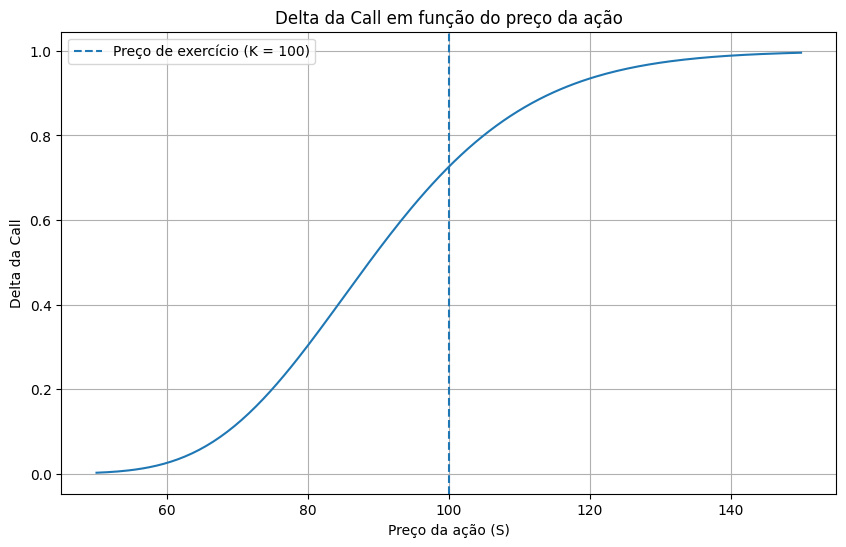

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Parâmetros
K = 100
r = 0.10
T = 1
sigma = 0.20

# Diferentes preços da ação
S = np.linspace(50, 150, 200)

# d1
d1 = (
    np.log(S / K)
    + (r + sigma**2 / 2) * T
) / (sigma * np.sqrt(T))

# Delta da Call
delta_call = norm.cdf(d1)

# Gráfico
plt.figure(figsize=(10,6))

plt.plot(S, delta_call)

plt.axvline(
    K,
    linestyle="--",
    label="Preço de exercício (K = 100)"
)

plt.xlabel("Preço da ação (S)")
plt.ylabel("Delta da Call")
plt.title("Delta da Call em função do preço da ação")

plt.legend()
plt.grid(True)

plt.show()

O gráfico mostra que o Delta da call aumenta conforme o preço da ação sobe (Gamma positivo).

Quando o preço do ativo está bem abaixo do preço de exercício, o Delta fica próximo de 0, à medida que o preço aumenta, o Delta cresce e se aproxima de 1.

Isso significa que, quanto maior o Delta, maior é a sensibilidade do preço da opção às variações no preço da ação.

Exercício 5

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# Preço inicial da PETR4
S0 = precos["PETR4"].iloc[-1]

# Volatilidade histórica anualizada
sigma = retornos["PETR4"].std() * np.sqrt(252)

# Parâmetros da opção
K = S0
r = 0.10
dias = 30
T = dias / 252

np.random.seed(42)

# Simulação do preço da PETR4
precos_simulados = [S0]

for i in range(dias):

    retorno = (
        (r - 0.5 * sigma**2) / 252
        + sigma / np.sqrt(252) * np.random.normal()
    )

    novo_preco = precos_simulados[-1] * np.exp(retorno)
    precos_simulados.append(novo_preco)

deltas = []

for i, S in enumerate(precos_simulados):

    tempo_restante = (dias - i) / 252

    if tempo_restante > 0:

        d1 = (
            np.log(S / K)
            + (r + sigma**2 / 2) * tempo_restante
        ) / (
            sigma * np.sqrt(tempo_restante)
        )

        delta = norm.cdf(d1)

    else:
        delta = 1 if S > K else 0

    deltas.append(delta)

delta_hedge = pd.DataFrame({
    "Preço PETR4": precos_simulados,
    "Delta": deltas
})

delta_hedge["Ações para hedge"] = (
    delta_hedge["Delta"] * 100
)

delta_hedge["Dia"] = range(len(delta_hedge))

delta_hedge["Ajuste diário"] = (
    delta_hedge["Ações para hedge"].diff()
)

delta_hedge.head(10)

,Preço PETR4,Delta,Ações para hedge,Dia,Ajuste diário
0,55.360000,0.561597,56.159714,0,NaN
1,56.071920,0.596832,59.683234,1,3.523520
2,55.877803,0.586492,58.649239,2,-1.033995
3,56.815416,0.633924,63.392436,3,4.743197
4,59.077110,0.739712,73.971218,4,10.578782
5,58.728335,0.726823,72.682345,5,-1.288873
6,58.381644,0.713166,71.316595,6,-1.365750
7,60.793009,0.815597,81.559721,7,10.243126
8,62.002763,0.859276,85.927645,8,4.367923
9,61.266739,0.839983,83.998345,9,-1.929300


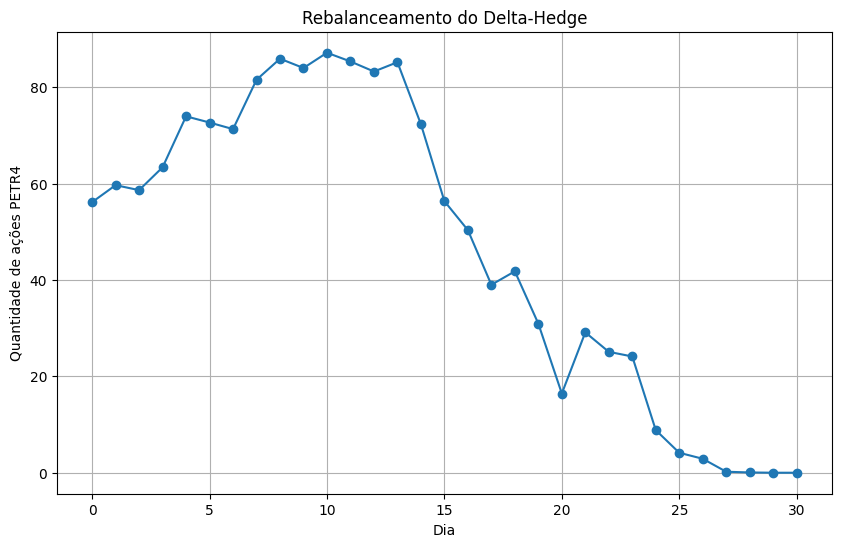

In [46]:
plt.figure(figsize=(10,6))

plt.plot(
    delta_hedge["Dia"],
    delta_hedge["Ações para hedge"],
    marker="o"
)

plt.xlabel("Dia")
plt.ylabel("Quantidade de ações PETR4")
plt.title("Rebalanceamento do Delta-Hedge")

plt.grid(True)
plt.show()

Foi realizada uma simulação de Delta-Hedge utilizando a PETR4 e uma posição vendida em 100 opções de compra. A cada período, o Delta da opção foi recalculado conforme o preço da ação e o tempo até o vencimento se alteravam.

Como o Delta variou ao longo da simulação, a quantidade de ações necessária para o hedge também precisou ser reajustada, por exemplo, um Delta de aproximadamente 0,56 exige a compra de cerca de 56 ações, enquanto um Delta de aproximadamente 0,86 exige cerca de 86 ações para compensar a exposição da posição vendida.

A simulação mostra que o Delta-Hedge é uma estratégia dinâmica, pois, conforme as condições da opção mudam, a posição no ativo também precisa ser rebalanceada para manter a exposição próxima de neutra.